In [1]:
%display latex

SageMath notebook. Needs `mpchebdif.sage` (arbitrary-precision Chebyshev differentiation matrices) in the same folder. The fundamental $\ell=2$ mode $M\omega = 0.48364 - 0.09676i$ reproduces the literature value.

# Scalar field in Schwarzschild BH in EF coordinates

In [2]:
# useful function for simplifying the coefficients of a differential equation 
def simplify_coefficients(eqn,fcnlist,depvar,order):
    var('out,cf')
    out=0
    cf=0
    for j in range(len(fcnlist)):
        for k in range(order+1):
            cf = eqn.coefficient(diff(fcnlist[j],k)).full_simplify().expand()
            out = out + cf*diff(fcnlist[j],depvar,k)
    return out

In [3]:
# round a complex number
var('x','order')
def roundc(x,order):
    return round(real(x),ndigits=order) + I*round(imag(x),ndigits=order)

In [4]:
BH = Manifold(4, 'BH', structure='Lorentzian')
print(BH)

4-dimensional Lorentzian manifold BH


In [5]:
H.<v,u,th,ph> = BH.chart(r"v u th:\vartheta ph:\varphi")
H

Chart (BH, (v, u, th, ph))

In [6]:
blackf = function('f')(u)
g = BH.metric()
g[0,0] = -blackf
g[0,1] = -1/u^2
g[2,2] = 1/u^2
g[3,3] = 1/u^2*sin(th)^2
g.display()

g = -f(u) dv⊗dv - 1/u^2 dv⊗du - 1/u^2 du⊗dv + u^(-2) dth⊗dth + sin(th)^2/u^2 dph⊗dph

In [7]:
riccitensor=g.ricci()
riccitensor.display()

Ric(g) = 1/2*u^4*f(u)*d^2(f)/du^2 dv⊗dv + 1/2*u^2*d^2(f)/du^2 dv⊗du + 1/2*u^2*d^2(f)/du^2 du⊗dv + (u*d(f)/du - f(u) + 1) dth⊗dth + (u*sin(th)^2*d(f)/du - f(u)*sin(th)^2 + sin(th)^2) dph⊗dph

In [8]:
bgeom=riccitensor[2,2].expr()
bgeom

u*diff(f(u), u) - f(u) + 1

In [9]:
desolve(bgeom,[f(u),u]).expand()

_C*u + 1

In [10]:
var('M')
fbh(u)=1-2*M*u
(g.ricci_scalar().expr().substitute_function(f,fbh) ).expand()

0

In [11]:
Ph=function('Phi')
Sfield = BH.scalar_field(Phi(v,u,th,ph) , latex_name=r'\Phi')
dSfield = Sfield.exterior_derivative();

In [12]:
var('μ')
eom = ((dSfield.hodge_dual(g)).exterior_derivative()).hodge_dual(g) + μ^2*Sfield

In [13]:
Eom=eom.expr()
Eom

-(u^4*f(u)*sin(th)^2*diff(Phi(v, u, th, ph), u, u) + u^4*sin(th)^2*diff(Phi(v, u, th, ph), u)*diff(f(u), u) - μ^2*Phi(v, u, th, ph)*sin(th)^2 - 2*u^2*sin(th)^2*diff(Phi(v, u, th, ph), v, u) + u^2*cos(th)*sin(th)*diff(Phi(v, u, th, ph), th) + u^2*sin(th)^2*diff(Phi(v, u, th, ph), th, th) + 2*u*sin(th)^2*diff(Phi(v, u, th, ph), v) + u^2*diff(Phi(v, u, th, ph), ph, ph))/sin(th)^2

In [14]:
Eom.expand()

-u^4*f(u)*diff(Phi(v, u, th, ph), u, u) - u^4*diff(Phi(v, u, th, ph), u)*diff(f(u), u) + μ^2*Phi(v, u, th, ph) + 2*u^2*diff(Phi(v, u, th, ph), v, u) - u^2*cos(th)*diff(Phi(v, u, th, ph), th)/sin(th) - u^2*diff(Phi(v, u, th, ph), th, th) - 2*u*diff(Phi(v, u, th, ph), v) - u^2*diff(Phi(v, u, th, ph), ph, ph)/sin(th)^2

In [15]:
var('l',latex_name="ℓ")
var('L2',latex_name=r"\mathcal{L}^2")
Eom2=Eom.subs(diff(Phi(v,u,th,ph),th,2)==-L2*Phi(v,u,th,ph),diff(Phi(v,u,th,ph),th)==0, diff(Phi(v,u,th,ph),ph,2)==0 )

In [16]:
Eom2.rational_simplify()

-u^4*f(u)*diff(Phi(v, u, th, ph), u, u) - u^4*diff(Phi(v, u, th, ph), u)*diff(f(u), u) + L2*u^2*Phi(v, u, th, ph) + μ^2*Phi(v, u, th, ph) + 2*u^2*diff(Phi(v, u, th, ph), v, u) - 2*u*diff(Phi(v, u, th, ph), v)

In [17]:
var('ω')
chifun=function('R') 
Phisubs(v,u,th,ph) = exp(-I*ω*v)*R(u)
eq1=(exp(I*ω*v)*Eom2.substitute_function( Phi , Phisubs  )).rational_simplify()
eq1

-u^4*f(u)*diff(R(u), u, u) - u^4*diff(R(u), u)*diff(f(u), u) + L2*u^2*R(u) + μ^2*R(u) - 2*(I*u^2*diff(R(u), u) - I*u*R(u))*ω

In [18]:
eq=simplify_coefficients(eq1/(u^4*f(u)),[R(u)],u,2)
eq

(L2/(u^2*f(u)) + μ^2/(u^4*f(u)) + 2*I*ω/(u^3*f(u)))*R(u) - (diff(f(u), u)/f(u) + 2*I*ω/(u^2*f(u)))*diff(R(u), u) - diff(R(u), u, u)

In [19]:
var('α')
eqM0=eq.substitute_function( f, fbh).subs(μ==0)
eqM0

-(L2/((2*M*u - 1)*u^2) + 2*I*ω/((2*M*u - 1)*u^3))*R(u) - 2*(M/(2*M*u - 1) - I*ω/((2*M*u - 1)*u^2))*diff(R(u), u) - diff(R(u), u, u)

In [20]:
var('α,β')
Rsubsinf(u)=exp(α/u)*u^(β)

In [21]:
taylor( (eqM0.substitute_function( R, Rsubsinf)*exp(-α/u)*u^(-β) ).expand() , u ,0,-4)

-(α^2 - 2*I*α*ω)/u^4

In [22]:
solve(_==0,α)

[α == 2*I*ω, α == 0]

The outgoing solution is the one with $\alpha = 2 i \omega$

In [23]:
taylor( (eqM0.substitute_function( R, Rsubsinf)*exp(-α/u)*u^(-β) ).expand() , u ,0,-3).subs(α == 2*I*ω)

-2*((4*M*ω + I*β - I)*ω - 2*I*β*ω + 2*I*ω)/u^3

In [24]:
solve(_==0,β)

[β == -4*I*M*ω + 1]

now for the local behavior on the horizon

In [25]:
RsubHor(u)=fbh(u)^(α)

In [26]:
taylor( fbh(u)^(-α+2)*eqM0.substitute_function( R, RsubHor).expand() , u, 1/(2*M), 0).simplify()

16*I*M^3*α*ω - 4*M^2*α^2

In [27]:
solve( _==0,α)

[α == 4*I*M*ω, α == 0]

In EF coordinates the infalling modes are the ones with $\alpha = 0$ on the horizon!

In [28]:
function('RR')(u)
Rsubs(u) = exp(2*I*ω/u) * u^(-4*I*M*ω) * RR(u)

In [29]:
eqRR0=(exp(-2*I*ω/u)*u^(+4*I*M*ω)*eqM0.substitute_function(R,Rsubs ))

In [30]:
eqRR1=simplify_coefficients(u^3*(1-u)*eqRR0.subs([M==1/2 , ω == 2*ω]),[RR(u)],u,2)
eqRR1

-(16*u^2*ω^2 + 16*u*ω^2 - L2*u + 4*I*ω)*RR(u) + (-8*I*u^3*ω + u^3 + 4*I*u*ω)*diff(RR(u), u) + (u^4 - u^3)*diff(RR(u), u, u)

Now this is still a singular differential equation but with exponents $0$ at $u=0$ and $1$ which means that there is a solution which is analytic for specific values of $\omega$ and these are the quasinormal frequencies.
It coincides with eq.(4.8) in 1709.0918.

In [31]:
function('ZZ')
RRsubs(u) = I * ZZ(u)
I*ω*(eqRR1.coefficient(ω,2)).substitute_function(RR,RRsubs)

16*(u^2 + u)*ω*ZZ(u)

In [32]:
A1 =  eqRR1.coefficient(ω,0)
A2 = (I*eqRR1.coefficient(ω,1))
B2 = (eqRR1.coefficient(ω,2))
display(A1,A2,B2)

u^3*diff(RR(u), u) + L2*u*RR(u) + (u^4 - u^3)*diff(RR(u), u, u)

-4*I*(2*I*u^3 - I*u)*diff(RR(u), u) + 4*RR(u)

-16*(u^2 + u)*RR(u)

Here we have set $ -i \omega RR(u) = ZZ(u)$. Then the differential equation becomes a first order matrix system of the form $A \Psi = -i\omega B . \Psi$ and the matrices A and B are
$ A= \left( \begin{array}{cc} 0 & 1\\ A1 & A2 \end{array}\right)$ and $ B = \left( \begin{array}{cc} 1 & 0\\ 0 & B2 \end{array}\right)$

In [128]:
import mpmath as mp

In [129]:
mp.mp.dps=30

In [130]:
load("mpchebdif.sage");

In [163]:
var('l')

l

In [280]:
N=100;  #gridsize
mp.mp.prec=192;
l=2;
xgrid,Ds=mpchebdif(N,2)  # chebgrid and derivates
ugrid=xgrid/2+1/2         # to interval [0,1]
um=mp.diag(ugrid) # the grid as a diagonal sage matrix
Du1=2*Ds[0] # 1st derivative on [1,0]
Du2=4*Ds[1] # 2nd derivative on [1,0]
#
A1m = um^int(3)*Du1+( um^int(4)-um^int(3) )*Du2 +l*(l+1)*um
A1mbc=A1m[0:N,0:N]   # Dirichlet bcs at infinite now
#
A2m = 4*(2*um^int(3)-um)*Du1 + 4*mp.eye(int(N+1))
A2mbc=A2m[0:N,0:N]   # D bcs 
#
B2m = -16*(um^int(2)+um)
B2mbc= B2m[0:N,0:N]  #D bcs
#

In [281]:
N

100

In [282]:
zerombc = mp.zeros(int(N))
onembc = mp.eye(int(N))
Amatrix = mp.zeros(int(2*N))
Amatrix[0:N,N:2*N] = I*onembc
Amatrix[N:2*N,0:N] = I*A1mbc
Amatrix[N:2*N,N:2*N] = I*A2mbc
Bmatrix = mp.zeros(int(2*N))
Bmatrix[0:N,0:N] = onembc
Bmatrix[N:2*N,N:2*N] = B2mbc

In [283]:
Evs, Vecsl = mp.eig(Bmatrix^(-int(1))*Amatrix)

In [284]:
convert = lambda *a: RDF(real(*a))+I*RDF(imag(*a)) # convert to usual double precision

In [285]:
evs=sorted(list(map(convert, Evs)),key=abs) 

In [286]:
evsrounded=list(map(lambda x: round(real(x),7)+I*round(imag(x),7),evs))

In [287]:
qnms=[]
for i in range(2*N):
    if real(evsrounded[i])>10^(-5): qnms = qnms+[evsrounded[i]]

In [288]:
for i in range(0,12): 
    print(qnms[i]) 

0.4836439 - 0.0967588*I
0.4638506 - 0.2956039*I
0.4305441 - 0.5085584*I
0.3938631 - 0.7380966*I
0.3612992 - 0.9799215*I
0.3348993 - 1.2284109*I
0.3138872 - 1.4799574*I
0.2969871 - 1.7327747*I
0.2831193 - 1.9860914*I
0.2712557 - 2.2394911*I
0.2614147 - 2.491976*I
0.2538803 - 2.7463848*I


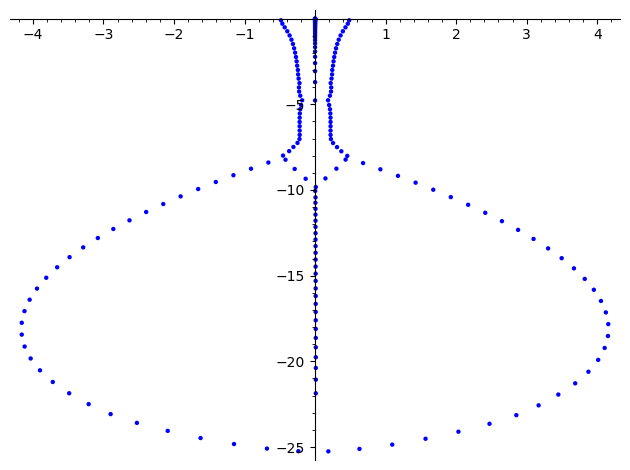

In [292]:
p0=list_plot(list(map( lambda x: (real(x),imag(x)) , evsrounded)))
#p2=list_plot(list(map( lambda x: (real(x),imag(x)) , qnmsl2[0:14])))
show(p0)